In [2]:
%pip install plotly
%pip install nbformat

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.7 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.7 MB 1.1 MB/s eta 0:00:09
   --- ------------------------------------ 0.8/9.7 MB 1.0 MB/s eta 0:00:09
   ---- ----------------------------------- 1.0/9.7 MB 1.0 MB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.7 MB 1.0 MB/s eta 0:00:09
   ----- ---------------------------------- 1.3/9.7 MB 1.0 MB/s eta 0:00:09
   ------ --------------------------------- 1.6/9.7 MB 1.0 MB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.7 MB 1.1 MB/s eta 0:00:08
   -------- ------------------------------- 2.1/9.7 MB 1.1 MB/s eta 0:00:08
   --------- ------------------------------ 2.4/9.7 MB 1.1 MB/s eta 0:00:07
   ---------- -----------------


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable

   ---------------------- ----------------- 4/7 [jsonschema-specifications]
   ---------------------------------- ----- 6/7 [nbformat]
   ---------------------------------------- 7/7 [nbformat]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import plotly.graph_objects as go
from IPython.display import HTML, display
from matplotlib.lines import Line2D

OBJECTIVES = ('rmse', 'nasa', 'both')
OBJECTIVE_COLORS = {
    'rmse': '#2878B5',
    'nasa': '#E07A2D',
    'both': '#3A923A',
}

## Características de configuraciones candidatas

Las gráficas siguientes muestran, por dataset y función objetivo, cuántos candidatos tienen cada función de activación, función de pérdida y número de capas ocultas.

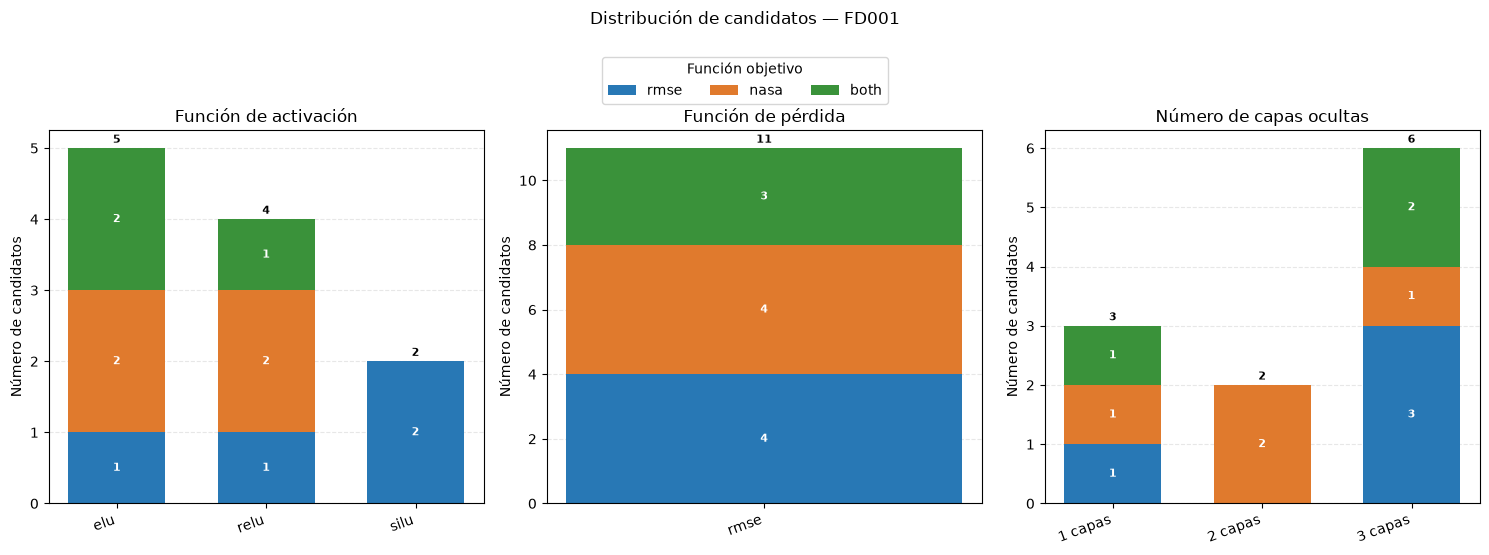

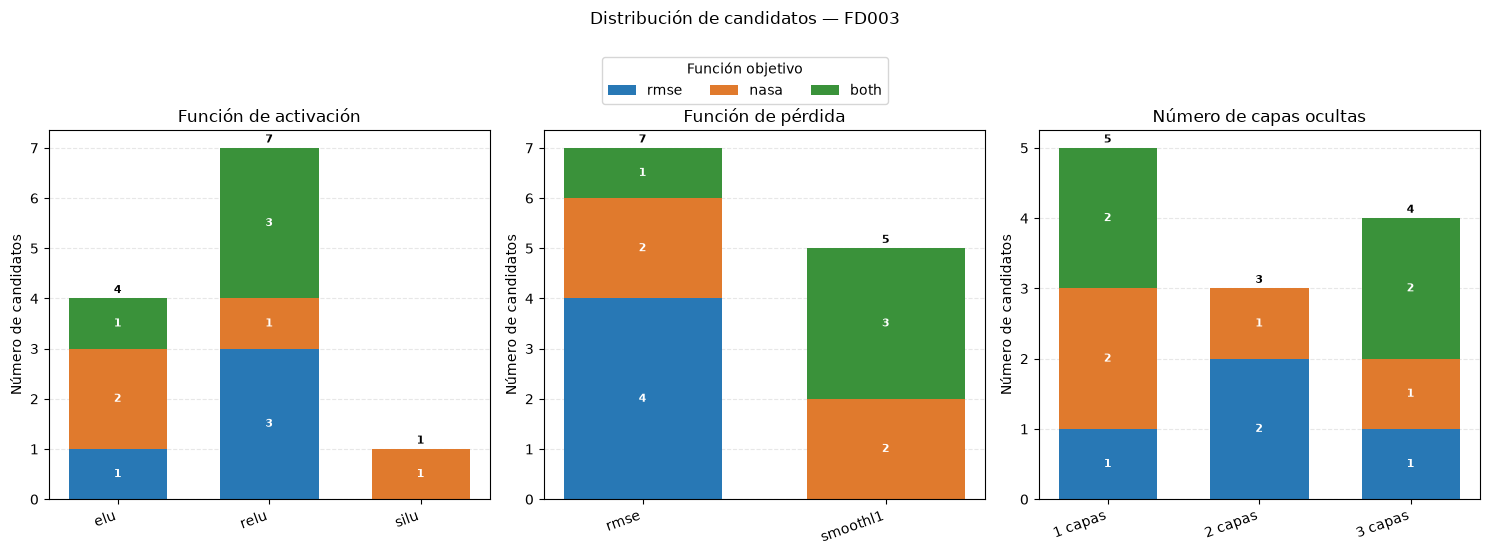

In [6]:
def plot_candidate_configuration_counts(dataset_name, results_dir='mopso_results'):
    """Grafica las frecuencias de activación, pérdida y capas por objetivo."""
    dataset_name = str(dataset_name).strip().upper()
    supported_datasets = {f'FD00{i}' for i in range(1, 5)}
    if dataset_name not in supported_datasets:
        choices = ', '.join(sorted(supported_datasets))
        raise ValueError(
            f'Dataset no admitido: {dataset_name!r}. Use uno de: {choices}.'
        )

    results_dir = Path(results_dir)
    configurations = {objective: [] for objective in OBJECTIVES}
    for objective in OBJECTIVES:
        json_path = results_dir / (
            f'{dataset_name}_mopso_final_candidates_v6_{objective}.json'
        )
        if not json_path.is_file():
            raise FileNotFoundError(f'No se encontró {json_path}.')
        with json_path.open('r', encoding='utf-8') as json_file:
            package = json.load(json_file)
        if package.get('dataset') != dataset_name or package.get('objective') != objective:
            raise ValueError(f'Metadatos inesperados en {json_path}.')
        candidates = package.get('candidates')
        if not isinstance(candidates, list) or not candidates:
            raise ValueError(f'No hay candidatos en {json_path}.')

        for candidate in candidates:
            architecture = candidate.get('architecture', {})
            hidden_sizes = architecture.get('hidden_sizes')
            activation = architecture.get('activation')
            training_loss = architecture.get('training_loss')
            if not isinstance(hidden_sizes, list) or not hidden_sizes:
                raise ValueError(f'Topología oculta inválida en {json_path}.')
            if not activation or not training_loss:
                raise ValueError(f'Falta activación o pérdida en {json_path}.')
            configurations[objective].append({
                'activation': str(activation),
                'training_loss': str(training_loss),
                'hidden_layers': len(hidden_sizes),
            })

    metrics = (
        ('activation', 'Función de activación'),
        ('training_loss', 'Función de pérdida'),
        ('hidden_layers', 'Número de capas ocultas'),
    )
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (metric, title) in zip(axes, metrics):
        categories = sorted({
            candidate[metric]
            for candidates in configurations.values()
            for candidate in candidates
        })
        positions = np.arange(len(categories))
        bottoms = np.zeros(len(categories), dtype=int)
        totals = np.zeros(len(categories), dtype=int)
        for objective in OBJECTIVES:
            counts = {
                category: sum(
                    candidate[metric] == category
                    for candidate in configurations[objective]
                )
                for category in categories
            }
            heights = np.array([counts[category] for category in categories])
            bars = ax.bar(
                positions,
                heights,
                bottom=bottoms,
                width=0.65,
                color=OBJECTIVE_COLORS[objective],
                label=objective,
            )
            ax.bar_label(
                bars,
                labels=[str(value) if value > 0 else '' for value in heights],
                label_type='center',
                color='white',
                fontsize=8,
                fontweight='bold',
            )
            bottoms += heights
            totals += heights
        ax.bar_label(
            ax.containers[-1],
            labels=[str(total) for total in totals],
            label_type='edge',
            padding=2,
            fontsize=8,
            fontweight='bold',
        )

        if metric == 'hidden_layers':
            category_labels = [f'{category} capas' for category in categories]
        else:
            category_labels = [str(category) for category in categories]
        ax.set_xticks(positions, category_labels, rotation=20, ha='right')
        ax.set_title(title)
        ax.set_ylabel('Número de candidatos')
        ax.grid(axis='y', linestyle='--', alpha=0.3)
        ax.set_axisbelow(True)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, title='Función objetivo', loc='upper center',
               ncol=len(OBJECTIVES), bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f'Distribución de candidatos — {dataset_name}', y=1.10)
    fig.tight_layout()
    plt.show()
    return fig, axes


for dataset in ('FD001', 'FD003'):
    plot_candidate_configuration_counts(dataset)

# Comparación de candidatos MOPSO

Las funciones comparan los tres archivos de resultados (`rmse`, `nasa` y `both`) para un dataset. Usan métricas `test_*`, convierten el NASA sumativo a promedio por motor para mostrarlo en escala lineal y mantienen el valor sumativo medido para aplicar los filtros NASA. Los intervalos bootstrap del 95% se muestran en ambas gráficas. Las estrellas marcan candidatos seleccionados.

In [13]:
def _required_number(mapping, key, context):
    if key not in mapping:
        raise KeyError(f'Falta el campo {key!r} en {context}.')
    value = float(mapping[key])
    if not np.isfinite(value):
        raise ValueError(f'El campo {key!r} no es finito en {context}.')
    return value


def compare_candidate_results(
    dataset_name,
    results_dir='mopso_results',
    test_rul_path=None,
    min_parameters=None,
    max_parameters=None,
    min_rmse=None,
    max_rmse=None,
    min_nasa=None,
    max_nasa=None
):
    """Grafica candidatos; filtros NASA usan el promedio por motor."""
    dataset_name = str(dataset_name).strip().upper()
    supported_datasets = {f'FD00{i}' for i in range(1, 5)}
    if dataset_name not in supported_datasets:
        choices = ', '.join(sorted(supported_datasets))
        raise ValueError(
            f'Dataset no admitido: {dataset_name!r}. Use uno de: {choices}.'
        )

    filter_bounds = {
        'parameter_count': (min_parameters, max_parameters),
        'rmse': (min_rmse, max_rmse),
        'nasa_score': (min_nasa, max_nasa),
    }
    normalized_bounds = {}
    for metric, (minimum, maximum) in filter_bounds.items():
        converted = []
        for label, value in (('mínimo', minimum), ('máximo', maximum)):
            if value is None:
                converted.append(None)
                continue
            number = float(value)
            if not np.isfinite(number):
                raise ValueError(f'El {label} de {metric} debe ser finito.')
            converted.append(number)
        if converted[0] is not None and converted[1] is not None and converted[0] > converted[1]:
            raise ValueError(f'El mínimo de {metric} no puede superar el máximo.')
        normalized_bounds[metric] = tuple(converted)

    results_dir = Path(results_dir)
    if test_rul_path is None:
        rul_filename = f'RUL_{dataset_name}.txt'
        rul_candidates = (
            Path('data') / 'CMAPSSData' / rul_filename,
            Path('data') / 'backup_root_files' / rul_filename,
            results_dir.parent / 'data' / 'CMAPSSData' / rul_filename,
            results_dir.parent / 'data' / 'backup_root_files' / rul_filename,
        )
        test_rul_path = next(
            (path for path in rul_candidates if path.is_file()), None
        )
        if test_rul_path is None:
            searched = ', '.join(str(path) for path in rul_candidates)
            raise FileNotFoundError(
                f'No se encontró {rul_filename}; rutas comprobadas: {searched}. '
                'Pase test_rul_path explícitamente.'
            )
    else:
        test_rul_path = Path(test_rul_path)
        if not test_rul_path.is_file():
            raise FileNotFoundError(f'No se encontró {test_rul_path}.')

    with test_rul_path.open('r', encoding='utf-8') as rul_file:
        test_engine_count = sum(1 for line in rul_file if line.strip())
    if test_engine_count <= 0:
        raise ValueError(f'No se encontraron motores en {test_rul_path}.')

    records = []
    for objective in OBJECTIVES:
        json_path = results_dir / (
            f'{dataset_name}_mopso_final_candidates_v6_{objective}.json'
        )
        if not json_path.is_file():
            raise FileNotFoundError(
                f'No se encontró {json_path}. Pase la carpeta de resultados '
                "con results_dir si no es 'mopso_results'."
            )

        with json_path.open('r', encoding='utf-8') as json_file:
            package = json.load(json_file)
        if package.get('dataset') != dataset_name:
            raise ValueError(
                f'El dataset declarado en {json_path} no coincide con '
                f'{dataset_name}.'
            )
        if package.get('objective') != objective:
            raise ValueError(
                f'El objetivo declarado en {json_path} no coincide con '
                f'{objective}.'
            )

        candidates = package.get('candidates')
        if not isinstance(candidates, list) or not candidates:
            raise ValueError(f'No hay candidatos en {json_path}.')

        for candidate in candidates:
            candidate_id = candidate.get('candidate_id')
            architecture = candidate.get('architecture', {})
            hidden_sizes = architecture.get('hidden_sizes')
            metrics = candidate.get('test_results', {})
            context = f'{json_path.name}, candidato {candidate_id!r}'
            if not candidate_id:
                raise ValueError(f'Falta candidate_id en {context}.')
            if not isinstance(hidden_sizes, list):
                raise ValueError(f'Falta architecture.hidden_sizes en {context}.')
            if not isinstance(metrics, dict):
                raise ValueError(f'test_results no es válido en {context}.')

            parameter_count = int(
                _required_number(candidate, 'parameter_count', context)
            )
            if parameter_count <= 0:
                raise ValueError(f'parameter_count debe ser positivo en {context}.')

            rmse = _required_number(metrics, 'test_rmse', context)
            nasa = _required_number(metrics, 'test_nasa', context)
            rmse_low = _required_number(metrics, 'test_rmse_ci95_lower', context)
            rmse_high = _required_number(metrics, 'test_rmse_ci95_upper', context)
            nasa_low = _required_number(metrics, 'test_nasa_ci95_lower', context)
            nasa_high = _required_number(metrics, 'test_nasa_ci95_upper', context)
            if rmse_low > rmse_high or nasa_low > nasa_high:
                raise ValueError(f'Los límites de confianza están invertidos en {context}.')
            records.append({
                'objective': objective,
                'candidate_id': str(candidate_id),
                'hidden_sizes': tuple(int(size) for size in hidden_sizes),
                'parameter_count': parameter_count,
                'rmse': rmse,
                'rmse_low': rmse_low,
                'rmse_high': rmse_high,
                'nasa_score': nasa,
                'nasa': nasa / test_engine_count,
                'nasa_low': nasa_low / test_engine_count,
                'nasa_high': nasa_high / test_engine_count,
                'selected_winner': bool(candidate.get('selected_winner', False)),
            })

    records = [
        record for record in records
        if all(
            (minimum is None or record[metric] >= minimum)
            and (maximum is None or record[metric] <= maximum)
            for metric, (minimum, maximum) in normalized_bounds.items()
        )
    ]
    if not records:
        raise ValueError(
            'Ningún candidato cumple los límites solicitados; amplíe o quite filtros.'
        )

    parameter_logs = np.log10([record['parameter_count'] for record in records])
    log_min = float(parameter_logs.min())
    log_range = float(parameter_logs.max() - log_min)
    bubble_areas = [
        70.0 + 230.0 * ((value - log_min) / log_range if log_range else 0.5)
        for value in parameter_logs
    ]

    bubble_sizes = [np.sqrt(area) for area in bubble_areas]
    hidden_layer_counts = sorted({len(record['hidden_sizes']) for record in records})
    fig = go.Figure()

    for hidden_layer_count in hidden_layer_counts:
        layer_legend_label = (
            f'{hidden_layer_count} capa oculta'
            if hidden_layer_count == 1
            else f'{hidden_layer_count} capas ocultas'
        )
        layer_legend_group = f'hidden-layers-{hidden_layer_count}'
        layer_has_legend_entry = False
        for objective in OBJECTIVES:
            objective_data = [
                record for record in records
                if record['objective'] == objective
                and len(record['hidden_sizes']) == hidden_layer_count
            ]
            if not objective_data:
                continue
            objective_sizes = [
                size for record, size in zip(records, bubble_sizes)
                if record['objective'] == objective
                and len(record['hidden_sizes']) == hidden_layer_count
            ]
            customdata = [
                [
                    record['candidate_id'],
                    str(record['hidden_sizes']),
                    record['parameter_count'],
                    record['rmse_low'],
                    record['rmse_high'],
                    record['nasa_low'],
                    record['nasa_high'],
                    record['nasa_score'],
                    objective,
                    record['selected_winner'],
                ]
                for record in objective_data
            ]
            fig.add_trace(go.Scatter(
                x=[record['rmse'] for record in objective_data],
                y=[record['nasa'] for record in objective_data],
                mode='markers+text',
                text=[f"{objective} {record['hidden_sizes']}" for record in objective_data],
                textposition='top right',
                textfont={'size': 9},
                customdata=customdata,
                name=layer_legend_label,
                legendgroup=layer_legend_group,
                showlegend=not layer_has_legend_entry,
                marker={
                    'size': [
                        13 if record['selected_winner'] else size
                        for record, size in zip(objective_data, objective_sizes)
                    ],
                    'symbol': [
                        'star' if record['selected_winner'] else 'circle'
                        for record in objective_data
                    ],
                    'color': OBJECTIVE_COLORS[objective],
                    'opacity': 0.72,
                    'line': {'color': 'white', 'width': 1},
                },
                error_x={
                    'type': 'data',
                    'symmetric': False,
                    'array': [record['rmse_high'] - record['rmse'] for record in objective_data],
                    'arrayminus': [record['rmse'] - record['rmse_low'] for record in objective_data],
                    'color': OBJECTIVE_COLORS[objective],
                    'thickness': 1,
                    'width': 4,
                },
                error_y={
                    'type': 'data',
                    'symmetric': False,
                    'array': [record['nasa_high'] - record['nasa'] for record in objective_data],
                    'arrayminus': [record['nasa'] - record['nasa_low'] for record in objective_data],
                    'color': OBJECTIVE_COLORS[objective],
                    'thickness': 1,
                    'width': 4,
                },
                hovertemplate=(
                    '<b>%{customdata[8]}</b> · candidato %{customdata[0]}'
                    '<br>Arquitectura: %{customdata[1]}'
                    '<br>Parámetros: %{customdata[2]:,.0f}'
                    '<br>RMSE: %{x:.4f} (IC 95%: %{customdata[3]:.4f}–%{customdata[4]:.4f})'
                    '<br>NASA medio por motor: %{y:.4g} '
                    '(IC 95%: %{customdata[5]:.4g}–%{customdata[6]:.4g})'
                    '<br>NASA sumativo: %{customdata[7]:.4g}'
                    '<extra></extra>'
                ),
            ))
            layer_has_legend_entry = True

    fig.update_layout(
        title=(
            f'Comparación interactiva de candidatos — {dataset_name}'
            '<br><sup>Color: rmse (azul), nasa (naranja), both (verde) · ★ = seleccionado</sup>'
        ),
        xaxis_title='RMSE de test',
        yaxis_title='NASA score medio por motor',
        yaxis_type='linear',
        template='plotly_white',
        width=1200,
        height=760,
        margin={'l': 80, 'r': 300, 't': 100, 'b': 70},
        legend={
            'title': 'Capas ocultas (clic para filtrar)',
            'x': 1.01,
            'y': 1.12,
            'xanchor': 'left',
            'groupclick': 'togglegroup',
        },
        hoverlabel={'namelength': -1},
    )
    #display(HTML(fig.to_html(include_plotlyjs='cdn')))
    return fig

In [14]:
compare_candidate_results('FD001', max_rmse=None, max_nasa=None)